# MiniMol embeddings

- This notebook generates embeddings across several datasets using the **MiniMol** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [1]:
from minimol import Minimol
import numpy as np
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw
import pandas as pd
import sklearn
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm

/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/minimol/model.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [2]:
model = Minimol()

# MCES

In [ ]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
embeddings = model(smiles.tolist())
embeddings = np.array(embeddings)

In [ ]:
X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/MiniMol MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [02:27<00:00,  2.30s/it]

Expected length: 2012094766
Written length: 2012094766


In [ ]:
np.save('MCES/MiniMol MCES embeddings.npy', embeddings)

In [ ]:
n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/MiniMol MCES pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:30<00:00, 2111.29it/s]


Expected: 2012094766
Written: 2012094766


# MCES figure example

  0%|          | 0/1 [00:00<?, ?it/s]/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
100%|██████████| 1/1 [00:04<00:00,  4.60s/it]

Cosine similarity: [[0.9536086]]


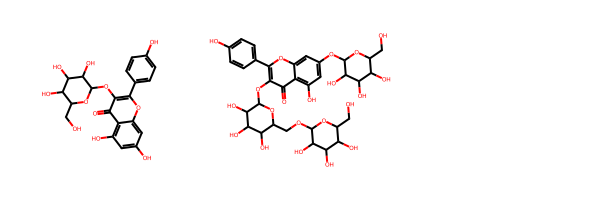

In [3]:
close_pair_a = "C1=CC(=CC=C1C2=C(C(=O)C3=C(C=C(C=C3O2)O)O)OC4C(C(C(C(O4)CO)O)O)O)O"
close_pair_b = "C1=CC(=CC=C1C2=C(C(=O)C3=C(C=C(C=C3O2)OC4C(C(C(C(O4)CO)O)O)O)O)OC5C(C(C(C(O5)COC6C(C(C(C(O6)CO)O)O)O)O)O)O)O"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = model([close_pair_a, close_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

  0%|          | 0/1 [00:00<?, ?it/s]/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
100%|██████████| 1/1 [00:05<00:00,  5.11s/it]

Cosine similarity: [[0.55598736]]


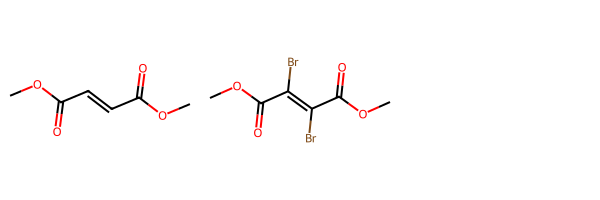

In [4]:
distant_pair_a = "COC(=O)C=CC(=O)OC"
distant_pair_b = "COC(=O)C(=C(C(=O)OC)Br)Br"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = model([distant_pair_a, distant_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [ ]:
embeddings = model(smiles)
embeddings = np.array(embeddings)
np.save('Biogen/MiniMol Biogen embeddings.npy', embeddings)

  0%|          | 0/36 [00:00<?, ?it/s]/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is depre

# ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data       = pd.read_csv(ZINC30K_PATH)[:30000]
smiles     = data['SMILES'].tolist()
embeddings = model(smiles)
np.save('ZINC/MiniMol ZINC30K embeddings.npy', embeddings)

  0%|          | 0/300 [00:00<?, ?it/s]/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/blake/miniconda3/envs/minimol/lib/python3.10/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is depr